# 02. 토큰화와 임베딩

이 노트북에서 하는 일: 같은 한국어 문장이 모델별로 어떻게 토큰화되는지 비교하고, Word2Vec 고정 임베딩과 KoBART 문맥 임베딩의 차이를 확인한다.

가이드 요구사항:

- KoBART BPE, KoGPT2 BPE, KoELECTRA WordPiece 토큰 분리 비교
- 모델별 토큰 길이 분포와 512·1,024토큰 초과 비율 비교
- Word2Vec으로 train 기사 단어 임베딩 학습 및 유사 단어 확인
- 동일 단어의 기본 임베딩과 문맥 반영 인코더 출력 비교
- 토큰 ID → 임베딩 → 인코더 → 디코더 logits의 shape 기록

이 노트북에서는 요약 모델을 파인튜닝하거나 test 성능을 평가하지 않는다.


## 1. 환경과 설정

In [1]:
import os
import sys
from pathlib import Path

PROJECT = Path(r"C:\Users\KDS-30\Desktop\Projects\06_Team_Project4")
assert PROJECT.exists(), "프로젝트 경로를 확인하세요."
assert Path(sys.prefix).resolve() == (PROJECT / ".venv").resolve(), (
    "커널을 Python 3.11 (Team4 News GPU)로 바꾸세요."
)

os.environ["HF_HOME"] = str(PROJECT / ".cache" / "huggingface")
os.environ["HF_HUB_DOWNLOAD_TIMEOUT"] = "120"
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"
os.environ["TOKENIZERS_PARALLELISM"] = "false"

RESULTS = PROJECT / "results" / "02_tokenize_embedding"
FIGURES = RESULTS / "figures"
RESULTS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

SEED = 42
DATASET_ID = "daekeun-ml/naver-news-summarization-ko"
MODEL_SPECS = {
    "KoBART_BPE": "gogamza/kobart-base-v2",
    "KoGPT2_BPE": "skt/kogpt2-base-v2",
    "KoELECTRA_WordPiece": "monologg/koelectra-base-v3-discriminator",
}
TOKENIZATION_EXAMPLE = "정부가 수출 중소기업의 물류난 해소를 위해 무역금융 규모를 40조 원 이상 확대한다"
WORD2VEC_MAX_DOCS = None  # 빠른 점검은 5000처럼 지정, 전체 분석은 None

print("Python:", sys.version.split()[0])
print("결과 폴더:", RESULTS)

Python: 3.11.9
결과 폴더: C:\Users\KDS-30\Desktop\Projects\06_Team_Project4\results\02_tokenize_embedding


In [2]:
import json
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from datasets import load_dataset
from gensim.models import Word2Vec
from huggingface_hub import HfApi
from konlpy.tag import Okt
from transformers import AutoTokenizer, BartForConditionalGeneration

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

device: cuda
GPU: NVIDIA GeForce RTX 5060 Laptop GPU


## 2. train 데이터와 모델 revision 확인

In [3]:
api = HfApi()
dataset_revision = api.dataset_info(DATASET_ID).sha
model_revisions = {
    name: api.model_info(model_id).sha
    for name, model_id in MODEL_SPECS.items()
}

raw_dataset = load_dataset(DATASET_ID, revision=dataset_revision)
train_df = raw_dataset["train"].to_pandas().reset_index(drop=True)

assert len(train_df) == 22194
assert train_df["document"].notna().all()

print("dataset revision:", dataset_revision)
display(pd.Series(model_revisions, name="model revision"))
print("train rows:", len(train_df))

dataset revision: 916dfe6aed651b2ecd9d04fa0a704f8953e90762


KoBART_BPE             f5899cc556216353e23ee36b66fad52b902066c5
KoGPT2_BPE             d0c0df48bf2b2c9350dd855021a5b216f560c0c7
KoELECTRA_WordPiece    68b30cd259f34a4b5aa8786392612ba2a2617fcc
Name: model revision, dtype: object

train rows: 22194


## 3. 같은 문장의 토크나이저 비교

KoBART와 KoGPT2는 BPE 계열이지만 학습 말뭉치와 어휘가 달라 분리 결과가 같지 않을 수 있다. KoELECTRA는 WordPiece를 사용하며 요약 생성 모델이 아니라 토큰화 방식 비교 대상으로만 사용한다.


In [4]:
tokenizers = {
    name: AutoTokenizer.from_pretrained(
        model_id,
        revision=model_revisions[name],
        clean_up_tokenization_spaces=False,
    )
    for name, model_id in MODEL_SPECS.items()
}

tokenization_rows = []
for name, tokenizer in tokenizers.items():
    tokens = tokenizer.tokenize(TOKENIZATION_EXAMPLE)
    token_ids = tokenizer.encode(TOKENIZATION_EXAMPLE, add_special_tokens=True)
    tokenization_rows.append({
        "tokenizer": name,
        "model_id": MODEL_SPECS[name],
        "tokenizer_class": tokenizer.__class__.__name__,
        "vocab_size": tokenizer.vocab_size,
        "tokens_without_special_count": len(tokens),
        "ids_with_special_count": len(token_ids),
        "tokens": " | ".join(tokens),
    })

tokenization_comparison_df = pd.DataFrame(tokenization_rows)
display(tokenization_comparison_df.T)
tokenization_comparison_df.to_csv(
    RESULTS / "tokenizer_example_comparison.csv",
    index=False,
    encoding="utf-8-sig",
)

You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.
You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.


config.json: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

tokenizer_config.json:   0%|          | 0.00/61.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/467 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

,0,1,2
tokenizer,KoBART_BPE,KoGPT2_BPE,KoELECTRA_WordPiece
model_id,gogamza/kobart-base-v2,skt/kogpt2-base-v2,monologg/koelectra-base-v3-discriminator
tokenizer_class,PreTrainedTokenizerFast,GPT2TokenizerFast,ElectraTokenizerFast
vocab_size,30000,51200,35000
tokens_without_special_count,17,19,20
ids_with_special_count,17,19,22
tokens,▁정부가 | ▁수출 | ▁중소기업의 | ▁물류 | 난 | ▁해 | 소를 | ▁위해 ...,▁정부가 | ▁수출 | ▁중소기업 | 의 | ▁물류 | 난 | ▁해 | 소를 | ▁...,정부 | ##가 | 수출 | 중소기업 | ##의 | 물류 | ##난 | 해소 | #...


## 4. train 전체 토큰 길이 비교

,tokenizer,rows,mean,median,p95,p99,max,over_512_count,over_512_pct,over_1024_count,over_1024_pct
0,KoBART_BPE,22194,418.12,357.0,970.00,1548.28,6781,6108,27.52,918,4.14
1,KoGPT2_BPE,22194,422.66,361.0,977.00,1564.07,6993,6231,28.08,943,4.25
2,KoELECTRA_WordPiece,22194,501.96,428.0,1163.35,1875.07,8431,8397,37.83,1692,7.62


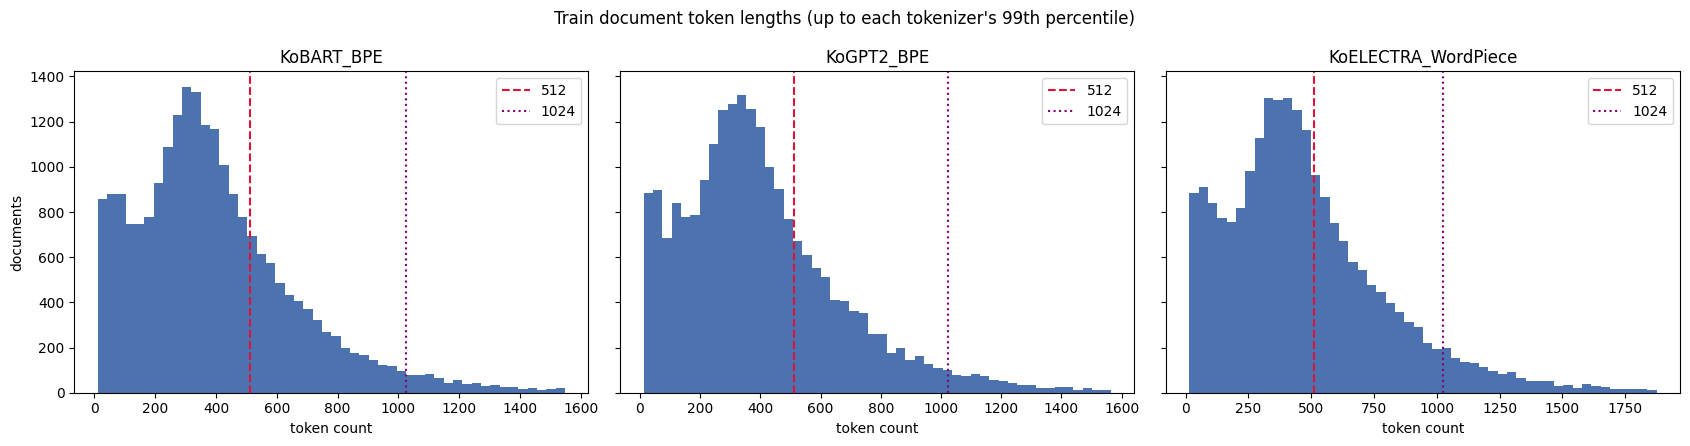

In [5]:
def token_lengths(tokenizer, texts, batch_size=256):
    lengths = []
    values = texts.astype(str).tolist()
    for start in range(0, len(values), batch_size):
        encoded = tokenizer(
            values[start:start + batch_size],
            add_special_tokens=True,
            truncation=False,
            return_attention_mask=False,
            return_token_type_ids=False,
            verbose=False,
        )
        lengths.extend(len(input_ids) for input_ids in encoded["input_ids"])
    return np.asarray(lengths, dtype=np.int32)

length_frames = []
length_summary_rows = []
for name, tokenizer in tokenizers.items():
    lengths = token_lengths(tokenizer, train_df["document"])
    length_frames.append(pd.DataFrame({"tokenizer": name, "tokens": lengths}))
    length_summary_rows.append({
        "tokenizer": name,
        "rows": len(lengths),
        "mean": lengths.mean(),
        "median": np.median(lengths),
        "p95": np.quantile(lengths, 0.95),
        "p99": np.quantile(lengths, 0.99),
        "max": lengths.max(),
        "over_512_count": int((lengths > 512).sum()),
        "over_512_pct": float((lengths > 512).mean() * 100),
        "over_1024_count": int((lengths > 1024).sum()),
        "over_1024_pct": float((lengths > 1024).mean() * 100),
    })

token_lengths_df = pd.concat(length_frames, ignore_index=True)
token_length_summary_df = pd.DataFrame(length_summary_rows)
display(token_length_summary_df.round(2))

token_length_summary_df.to_csv(
    RESULTS / "token_length_comparison.csv", index=False, encoding="utf-8-sig"
)

fig, axes = plt.subplots(1, len(MODEL_SPECS), figsize=(17, 4.5), sharey=True)
for axis, (name, group) in zip(axes, token_lengths_df.groupby("tokenizer", sort=False)):
    upper = group["tokens"].quantile(0.99)
    axis.hist(group.loc[group["tokens"].le(upper), "tokens"], bins=50, color="#4C72B0")
    axis.axvline(512, color="crimson", linestyle="--", label="512")
    axis.axvline(1024, color="purple", linestyle=":", label="1024")
    axis.set_title(name)
    axis.set_xlabel("token count")
    axis.legend()
axes[0].set_ylabel("documents")
plt.suptitle("Train document token lengths (up to each tokenizer's 99th percentile)")
plt.tight_layout()
plt.savefig(FIGURES / "token_length_comparison.png", dpi=160, bbox_inches="tight")
plt.show()

## 5. KoBART와 KoGPT2 구조 비교 및 모델 선택

KoBART와 KoGPT2는 모두 한국어 생성에 사용할 수 있지만 구조와 학습 입력 방식이 다르다. 이 프로젝트는 본문 전체를 읽고 요약을 생성하는 `document → summary` task이므로, 구조 비교와 토큰 길이 결과를 함께 근거로 모델을 선택한다. KoELECTRA는 생성 모델이 아니므로 토큰화 비교 대상으로만 둔다.

In [ ]:
architecture_comparison_df = pd.DataFrame([
    {
        "model": "KoBART",
        "tokenization": "BPE",
        "architecture": "encoder-decoder",
        "document_handling": "encoder가 본문 전체를 읽어 문맥 표현 생성",
        "summary_training": "decoder가 정답 summary 토큰을 순차 예측",
        "summarization_fit": "document → summary 구조와 직접 일치",
        "decision": "selected",
    },
    {
        "model": "KoGPT2",
        "tokenization": "BPE",
        "architecture": "decoder-only",
        "document_handling": "본문과 summary를 하나의 인과적(causal) 시퀀스로 연결",
        "summary_training": "앞 토큰을 바탕으로 다음 토큰 예측; 본문 부분 loss mask 필요",
        "summarization_fit": "가능하지만 별도 입력 형식과 학습 구현이 필요",
        "decision": "not selected",
    },
    {
        "model": "KoELECTRA",
        "tokenization": "WordPiece",
        "architecture": "encoder-only discriminator",
        "document_handling": "본문 표현을 생성하지만 요약 decoder가 없음",
        "summary_training": "문장 생성용 학습 구조가 아님",
        "summarization_fit": "분류·판별에는 적합, 생성 요약에는 부적합",
        "decision": "tokenization comparison only",
    },
])

kobart_length = token_length_summary_df.loc[
    token_length_summary_df["tokenizer"].eq("KoBART_BPE")
].iloc[0]
kogpt2_length = token_length_summary_df.loc[
    token_length_summary_df["tokenizer"].eq("KoGPT2_BPE")
].iloc[0]

selection_evidence_df = pd.DataFrame([
    {
        "criterion": "요약 task 구조 적합성",
        "evidence": "KoBART는 encoder-decoder로 document → summary를 직접 모델링",
        "conclusion": "KoBART 선택",
    },
    {
        "criterion": "토크나이저·사전학습 가중치 호환성",
        "evidence": "KoBART BPE token ID와 KoBART 사전학습 임베딩을 동일한 쌍으로 사용",
        "conclusion": "KoBART BPE 유지",
    },
    {
        "criterion": "본문 토큰 길이",
        "evidence": (
            f"KoBART 평균 {kobart_length['mean']:.1f}, 512 초과 {kobart_length['over_512_pct']:.2f}% / "
            f"KoGPT2 평균 {kogpt2_length['mean']:.1f}, 512 초과 {kogpt2_length['over_512_pct']:.2f}%"
        ),
        "conclusion": "길이 면에서도 KoBART가 불리하지 않음",
    },
])

display(architecture_comparison_df)
display(selection_evidence_df)
architecture_comparison_df.to_csv(
    RESULTS / "model_architecture_comparison.csv", index=False, encoding="utf-8-sig"
)
selection_evidence_df.to_csv(
    RESULTS / "kobart_selection_evidence.csv", index=False, encoding="utf-8-sig"
)
(RESULTS / "model_selection_decision.json").write_text(
    json.dumps({
        "selected_model": "gogamza/kobart-base-v2",
        "decision": "KoBART를 본문-요약 encoder-decoder 파인튜닝 모델로 사용",
        "note": "이 노트북은 구조·토큰화 근거를 비교한 것이며, KoBART와 KoGPT2의 동일 조건 성능 대결은 수행하지 않음",
    }, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

## 6. Word2Vec 고정 임베딩

수업에서 사용한 `Okt`로 train 기사를 형태소 단위로 나누고 Word2Vec을 학습한다. Word2Vec에서는 한 단어가 문맥과 관계없이 하나의 고정 벡터를 가진다.

`WORD2VEC_MAX_DOCS=None`이면 train 전체를 사용한다. 실행 시간을 먼저 확인하려면 설정 셀에서 5,000처럼 지정할 수 있다.


In [6]:
word2vec_source = train_df["document"]
if WORD2VEC_MAX_DOCS is not None:
    word2vec_source = word2vec_source.sample(
        n=min(WORD2VEC_MAX_DOCS, len(word2vec_source)),
        random_state=SEED,
    )

okt = Okt()
word2vec_corpus = []
for index, document in enumerate(word2vec_source.astype(str), start=1):
    morphs = okt.morphs(document, stem=True)
    if morphs:
        word2vec_corpus.append(morphs)
    if index % 1000 == 0:
        print(f"형태소 분석: {index:,}/{len(word2vec_source):,}")

word2vec_model = Word2Vec(
    sentences=word2vec_corpus,
    vector_size=100,
    window=5,
    min_count=5,
    workers=1,
    sg=1,
    seed=SEED,
    epochs=5,
)
word2vec_model.save(str(RESULTS / "news_word2vec.model"))

similar_word_rows = []
for query in ["수출", "반도체", "기업", "경제"]:
    if query not in word2vec_model.wv:
        print(f"Word2Vec 어휘에 없음: {query}")
        continue
    for rank, (word, similarity) in enumerate(
        word2vec_model.wv.most_similar(query, topn=10), start=1
    ):
        similar_word_rows.append({
            "query": query,
            "rank": rank,
            "similar_word": word,
            "cosine_similarity": similarity,
        })

word2vec_similar_words_df = pd.DataFrame(similar_word_rows)
display(word2vec_similar_words_df)
word2vec_similar_words_df.to_csv(
    RESULTS / "word2vec_similar_words.csv", index=False, encoding="utf-8-sig"
)

형태소 분석: 1,000/22,194
형태소 분석: 2,000/22,194
형태소 분석: 3,000/22,194
형태소 분석: 4,000/22,194
형태소 분석: 5,000/22,194
형태소 분석: 6,000/22,194
형태소 분석: 7,000/22,194
형태소 분석: 8,000/22,194
형태소 분석: 9,000/22,194
형태소 분석: 10,000/22,194
형태소 분석: 11,000/22,194
형태소 분석: 12,000/22,194
형태소 분석: 13,000/22,194
형태소 분석: 14,000/22,194
형태소 분석: 15,000/22,194
형태소 분석: 16,000/22,194
형태소 분석: 17,000/22,194
형태소 분석: 18,000/22,194
형태소 분석: 19,000/22,194
형태소 분석: 20,000/22,194
형태소 분석: 21,000/22,194
형태소 분석: 22,000/22,194


,query,rank,similar_word,cosine_similarity
0,수출,1,교역,0.659205
1,수출,2,3424,0.656423
2,수출,3,34.0%,0.633179
3,수출,4,수출입,0.632438
4,수출,5,4496,0.631038
5,수출,6,對,0.629846
6,수출,7,577억,0.628941
7,수출,8,70억달러,0.622664
8,수출,9,242억,0.619676
9,수출,10,3503억달러,0.619079


## 6. KoBART 기본 임베딩과 문맥 임베딩 비교

같은 `수출`이라는 표현을 서로 다른 문장에 넣는다. 입력 임베딩은 토큰 자체를 나타내고, 인코더 출력은 문장 전체를 읽은 뒤 문맥이 반영된 벡터다.


In [7]:
kobart_tokenizer = tokenizers["KoBART_BPE"]
kobart_model = BartForConditionalGeneration.from_pretrained(
    MODEL_SPECS["KoBART_BPE"],
    revision=model_revisions["KoBART_BPE"],
    use_safetensors=True,
).to(device)
kobart_model.eval()

context_sentences = [
    "한국 경제에서 수출 비중이 크게 증가했다.",
    "정부는 수출 기업의 물류비를 지원하기로 했다.",
]
keyword = "수출"

def keyword_vectors(sentence, keyword):
    encoded = kobart_tokenizer(
        sentence,
        return_tensors="pt",
        return_offsets_mapping=True,
        return_token_type_ids=False,
    )
    offsets = encoded.pop("offset_mapping")[0].tolist()
    keyword_start = sentence.index(keyword)
    keyword_end = keyword_start + len(keyword)
    positions = [
        index
        for index, (start, end) in enumerate(offsets)
        if end > keyword_start and start < keyword_end
    ]
    assert positions, f"키워드 토큰 위치를 찾지 못했습니다: {sentence}"

    model_inputs = {key: value.to(device) for key, value in encoded.items()}
    with torch.no_grad():
        input_embeddings = kobart_model.model.shared(model_inputs["input_ids"])
        encoder_output = kobart_model.model.encoder(**model_inputs).last_hidden_state

    input_vector = input_embeddings[0, positions].mean(dim=0).cpu()
    contextual_vector = encoder_output[0, positions].mean(dim=0).cpu()
    keyword_tokens = kobart_tokenizer.convert_ids_to_tokens(
        model_inputs["input_ids"][0, positions].detach().cpu().tolist()
    )
    return input_vector, contextual_vector, keyword_tokens

first_input, first_context, first_tokens = keyword_vectors(context_sentences[0], keyword)
second_input, second_context, second_tokens = keyword_vectors(context_sentences[1], keyword)

embedding_comparison_df = pd.DataFrame([
    {
        "representation": "input_embedding",
        "cosine_similarity": F.cosine_similarity(
            first_input.unsqueeze(0), second_input.unsqueeze(0)
        ).item(),
        "interpretation": "토큰 자체의 기본 벡터",
    },
    {
        "representation": "encoder_contextual_output",
        "cosine_similarity": F.cosine_similarity(
            first_context.unsqueeze(0), second_context.unsqueeze(0)
        ).item(),
        "interpretation": "문장 전체 문맥이 반영된 벡터",
    },
])

print("문장 1의 키워드 토큰:", first_tokens)
print("문장 2의 키워드 토큰:", second_tokens)
display(embedding_comparison_df)
embedding_comparison_df.to_csv(
    RESULTS / "embedding_context_comparison.csv", index=False, encoding="utf-8-sig"
)

You passed along `num_labels=3` with an incompatible id to label map: {'0': 'NEGATIVE', '1': 'POSITIVE'}. The number of labels wil be overwritten to 2.


문장 1의 키워드 토큰: ['▁수출']
문장 2의 키워드 토큰: ['▁수출']


,representation,cosine_similarity,interpretation
0,input_embedding,1.000000,토큰 자체의 기본 벡터
1,encoder_contextual_output,0.355976,문장 전체 문맥이 반영된 벡터


## 7. KoBART 내부 데이터 흐름과 shape

In [8]:
sample_text = train_df.loc[0, "document"]
sample_inputs = kobart_tokenizer(
    sample_text,
    return_tensors="pt",
    max_length=512,
    truncation=True,
    return_token_type_ids=False,
)
sample_inputs = {key: value.to(device) for key, value in sample_inputs.items()}

decoder_start_token_id = kobart_model.config.decoder_start_token_id
if decoder_start_token_id is None:
    decoder_start_token_id = (
        kobart_tokenizer.bos_token_id
        if kobart_tokenizer.bos_token_id is not None
        else kobart_tokenizer.eos_token_id
    )
decoder_input_ids = torch.tensor([[decoder_start_token_id]], device=device)

with torch.no_grad():
    input_embeddings = kobart_model.model.shared(sample_inputs["input_ids"])
    encoder_output = kobart_model.model.encoder(**sample_inputs).last_hidden_state
    model_output = kobart_model(
        **sample_inputs,
        decoder_input_ids=decoder_input_ids,
    )

shape_log = {
    "input_ids": list(sample_inputs["input_ids"].shape),
    "attention_mask": list(sample_inputs["attention_mask"].shape),
    "token_embedding": list(input_embeddings.shape),
    "encoder_last_hidden_state": list(encoder_output.shape),
    "decoder_input_ids": list(decoder_input_ids.shape),
    "decoder_logits": list(model_output.logits.shape),
    "hidden_size": kobart_model.config.d_model,
    "vocab_size": kobart_model.config.vocab_size,
}

display(pd.Series(shape_log, name="shape"))
(RESULTS / "kobart_shape_log.json").write_text(
    json.dumps(shape_log, ensure_ascii=False, indent=2), encoding="utf-8"
)

input_ids                         [1, 315]
attention_mask                    [1, 315]
token_embedding              [1, 315, 768]
encoder_last_hidden_state    [1, 315, 768]
decoder_input_ids                   [1, 1]
decoder_logits               [1, 1, 30000]
hidden_size                            768
vocab_size                           30000
Name: shape, dtype: object

334

## 8. 해석 기준과 산출물

실행 후 다음 내용을 정리한다.

1. 동일 문장이 모델별로 몇 토큰으로 나뉘었는가?
2. 어떤 토크나이저에서 512·1,024토큰 초과가 더 많은가?
3. Word2Vec에서 주요 경제·IT 단어와 가까운 단어는 무엇인가?
4. 같은 단어의 입력 임베딩과 문맥 임베딩 cosine similarity가 어떻게 다른가?
5. 토큰 ID부터 decoder logits까지 각 텐서 shape는 무엇을 의미하는가?


In [9]:
run_summary = {
    "dataset_id": DATASET_ID,
    "dataset_revision": dataset_revision,
    "model_specs": MODEL_SPECS,
    "model_revisions": model_revisions,
    "seed": SEED,
    "tokenization_example": TOKENIZATION_EXAMPLE,
    "train_rows_for_token_lengths": len(train_df),
    "word2vec_source_rows": len(word2vec_source),
    "word2vec_vector_size": word2vec_model.vector_size,
    "word2vec_window": word2vec_model.window,
    "word2vec_min_count": word2vec_model.min_count,
    "context_sentences": context_sentences,
    "context_keyword": keyword,
}
(RESULTS / "run_summary.json").write_text(
    json.dumps(run_summary, ensure_ascii=False, indent=2), encoding="utf-8"
)

for path in sorted(RESULTS.rglob("*")):
    if path.is_file():
        print("-", path.relative_to(PROJECT))

- results\02_tokenize_embedding\embedding_context_comparison.csv
- results\02_tokenize_embedding\figures\token_length_comparison.png
- results\02_tokenize_embedding\kobart_shape_log.json
- results\02_tokenize_embedding\news_word2vec.model
- results\02_tokenize_embedding\run_summary.json
- results\02_tokenize_embedding\token_length_comparison.csv
- results\02_tokenize_embedding\tokenizer_example_comparison.csv
- results\02_tokenize_embedding\word2vec_similar_words.csv
